Dataset Summary:
  StudentID  WeeklyStudyHours  AttendanceRate  PreviousScore  InternetAccess  \
0  STU_1000              10.6            58.4           81.7               1   
1  STU_1001              23.9            63.9           41.4               1   
2  STU_1002              18.8            58.9           41.2               1   
3  STU_1003              15.8            54.4           57.8               1   
4  STU_1004               5.6            56.0           66.9               1   

   FinalGrade  
0        74.5  
1        79.2  
2        65.3  
3        69.3  
4        64.0  

Descriptive Statistics:
        WeeklyStudyHours  AttendanceRate  PreviousScore  InternetAccess  \
count         600.00000      600.000000     600.000000      600.000000   
mean           13.57000       74.764500      67.187000        0.801667   
std             6.86119       14.547935      15.994014        0.399077   
min             2.10000       50.200000      40.300000        0.000000   
25%       

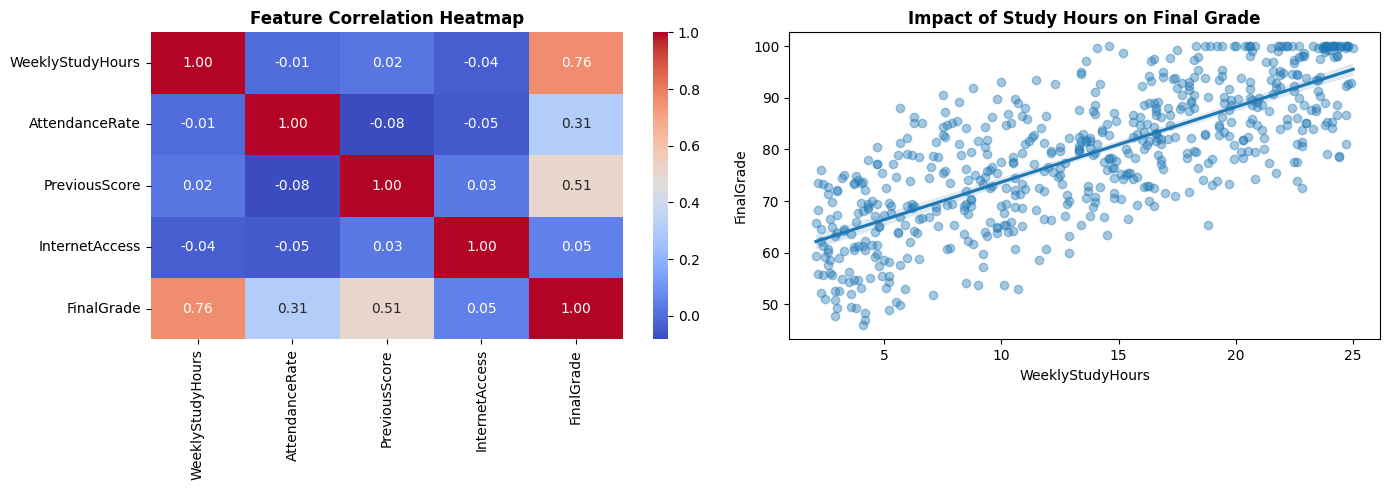


Model Performance (R² Score): 0.943
Mean Squared Error: 9.862


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Synthetic realistic academic performance dataset generate karna
np.random.seed(42)
n_students = 600

study_hours = np.random.uniform(2, 25, n_students)
attendance_rate = np.random.uniform(50, 100, n_students)
previous_scores = np.random.uniform(40, 95, n_students)
internet_access = np.random.choice([0, 1], n_students, p=[0.2, 0.8])

# Final score formula with noise
final_grade = (
    study_hours * 1.5 +
    attendance_rate * 0.35 +
    previous_scores * 0.45 +
    internet_access * 3.0 +
    np.random.normal(0, 3, n_students)
)
final_grade = np.clip(final_grade, 0, 100)

df_students = pd.DataFrame({
    'StudentID': [f'STU_{1000+i}' for i in range(n_students)],
    'WeeklyStudyHours': np.round(study_hours, 1),
    'AttendanceRate': np.round(attendance_rate, 1),
    'PreviousScore': np.round(previous_scores, 1),
    'InternetAccess': internet_access,
    'FinalGrade': np.round(final_grade, 1)
})

print("Dataset Summary:")
print(df_students.head())
print("\nDescriptive Statistics:\n", df_students.describe())

# 2. Visual Analytics (Correlation Heatmap & Study Hours vs Grade)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

numeric_cols = ['WeeklyStudyHours', 'AttendanceRate', 'PreviousScore', 'InternetAccess', 'FinalGrade']
sns.heatmap(df_students[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0])
axes[0].set_title('Feature Correlation Heatmap', fontweight='bold')

sns.regplot(data=df_students, x='WeeklyStudyHours', y='FinalGrade', ax=axes[1], color='#1f77b4', scatter_kws={'alpha':0.4})
axes[1].set_title('Impact of Study Hours on Final Grade', fontweight='bold')

plt.tight_layout()
plt.show()

# 3. Simple Predictive Model (Linear Regression)
X = df_students[['WeeklyStudyHours', 'AttendanceRate', 'PreviousScore', 'InternetAccess']]
y = df_students['FinalGrade']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

preds = model.predict(X_test)
print(f"\nModel Performance (R² Score): {r2_score(y_test, preds):.3f}")
print(f"Mean Squared Error: {mean_squared_error(y_test, preds):.3f}")